## Linear Kernel SVC

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from matplotlib.colors import ListedColormap

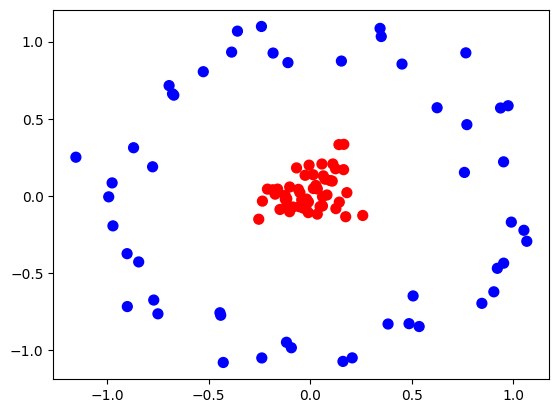

In [4]:
from sklearn.datasets import make_circles

X , y = make_circles(100,factor=.1,noise=.1)

plt.scatter(X[:,0],X[:,1],c=y,s=50,cmap='bwr')

In [5]:
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2)

In [6]:
classifier = SVC(kernel='linear')
classifier.fit(X_train ,y_train.ravel())
y_pred = classifier.predict(X_test)

In [7]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.45

In [9]:
zero_one_colormap = ListedColormap(('blue', 'red'))

def plot_decision_boundary(X, y, clf):

    X_set, y_set = X, y

    X1, X2 = np.meshgrid(
        np.arange(
            start=X_set[:, 0].min() - 1,
            stop=X_set[:, 0].max() + 1,
            step=0.01
        ),
        np.arange(
            start=X_set[:, 1].min() - 1,
            stop=X_set[:, 1].max() + 1,
            step=0.01
        )
    )

    plt.contour(
        X1,
        X2,
        clf.predict(
            np.array([X1.ravel(), X2.ravel()]).T
        ).reshape(X1.shape),
        alpha=0.75,
        cmap=zero_one_colormap
    )

    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2.min(), X2.max())

    for i, j in enumerate(np.unique(y_set)):
        plt.scatter(
            X_set[y_set == j, 0],
            X_set[y_set == j, 1],
            c=zero_one_colormap(i),
            label=j
        )

    plt.title('SVM Decision Boundary')
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.legend()

    return plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_27580\401792838.py:34: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(


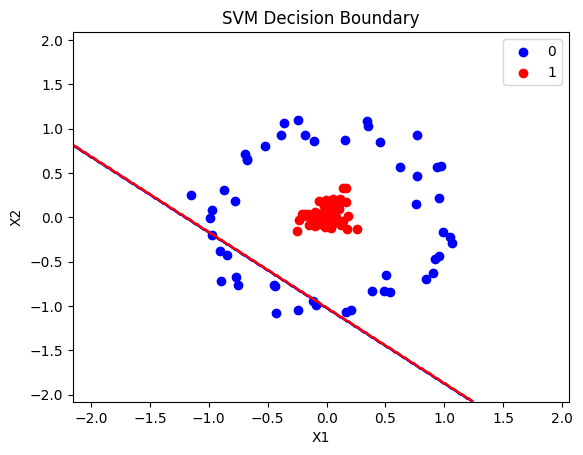

In [11]:
plot_decision_boundary(X,y,classifier)

## RBF Kernel SVC

In [27]:
def plot_3d(X,y):
    r = np.exp(-(X ** 2).sum(1)) # RDF Function
    # sum(1) adds X and y coordinates of points
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:,0],X[:,1],r,c=y,s=100,cmap='bwr')
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.set_zlabel('y')
    return ax

<Axes3D: xlabel='X1', ylabel='X2', zlabel='y'>

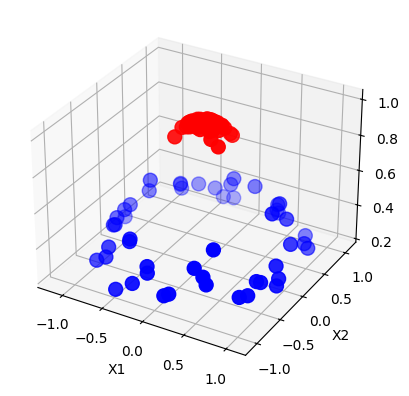

In [13]:
plot_3d(X,y)

In [16]:
rbf_classifier = SVC(kernel='rbf')
rbf_classifier.fit(X_train,y_train)
accuracy_score(rbf_classifier.predict(X_test),y_test)

1.0

##### 100% accuracy here for RBF Kernel SVM

C:\Users\DELL\AppData\Local\Temp\ipykernel_27580\401792838.py:34: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(


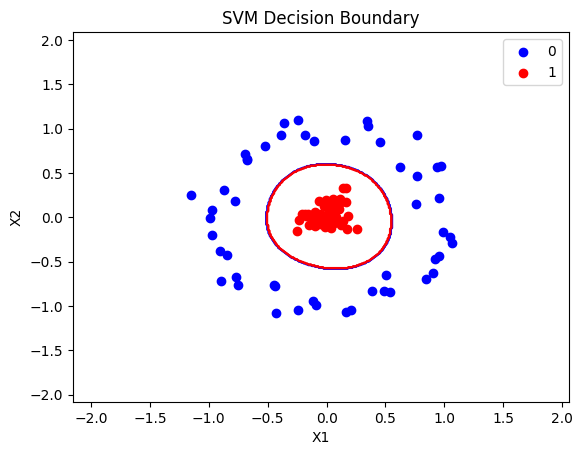

In [17]:
plot_decision_boundary(X,y,rbf_classifier)

## Polynomial Kernel SVC

In [23]:
poly_classifier = SVC(kernel='poly') # Degree default = 3
poly_classifier.fit(X_train,y_train)
y_pred = poly_classifier.predict(X_test)

In [21]:
accuracy_score(y_pred,y_test)

0.5

C:\Users\DELL\AppData\Local\Temp\ipykernel_27580\401792838.py:34: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(


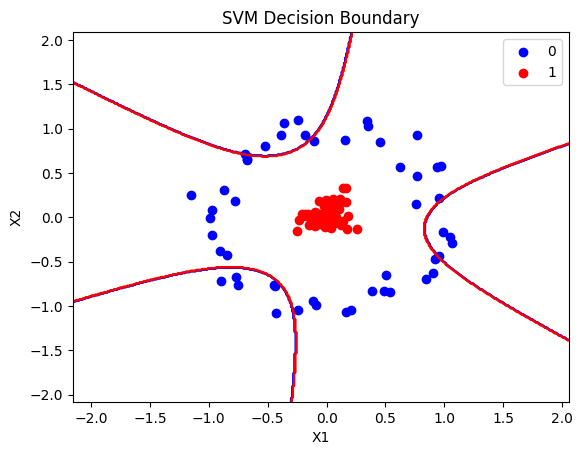

In [22]:
plot_decision_boundary(X,y,poly_classifier)

We can use different values of degree to get different results

In [24]:
poly_classifier = SVC(kernel='poly',degree=2) 
poly_classifier.fit(X_train,y_train)
y_pred = poly_classifier.predict(X_test)

In [25]:
accuracy_score(y_pred,y_test)

1.0

C:\Users\DELL\AppData\Local\Temp\ipykernel_27580\401792838.py:34: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(


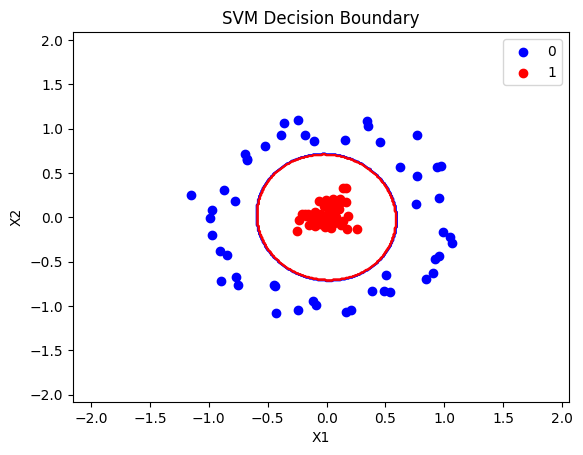

In [26]:
plot_decision_boundary(X,y,poly_classifier)